In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid')

from src.data.loader import load_raw_data, basic_clean
from src.features.engineering import add_behavioural_features

df = basic_clean(load_raw_data())
print(f'Shape: {df.shape}')
df.head()

2026-10-31 20:59:01,248 | INFO     | src.data.loader | load_raw_data:113 | Loading dataset from C:\All\why\data\raw\UCI_Credit_Card.csv


Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## Target balance
#
The dataset is moderately imbalanced: ~22% of clients default. This guides
the choice of metrics (F1, PR AUC) and class weighting in the models.

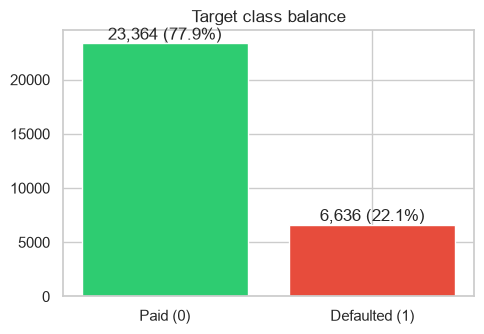

In [2]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = df['default_payment_next_month'].value_counts().sort_index()
bars = ax.bar(['Paid (0)', 'Defaulted (1)'], counts.values, color=['#2ecc71', '#e74c3c'])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v, f'{v:,} ({v/len(df):.1%})', ha='center', va='bottom')
ax.set_title('Target class balance')
plt.tight_layout()
plt.savefig('../reports/figures/01_class_balance.png', dpi=110)
plt.show()

## Demographics
#
Credit limit, age and the social attributes. Numeric attributes are aggregate
risk proxies rather than causal features.

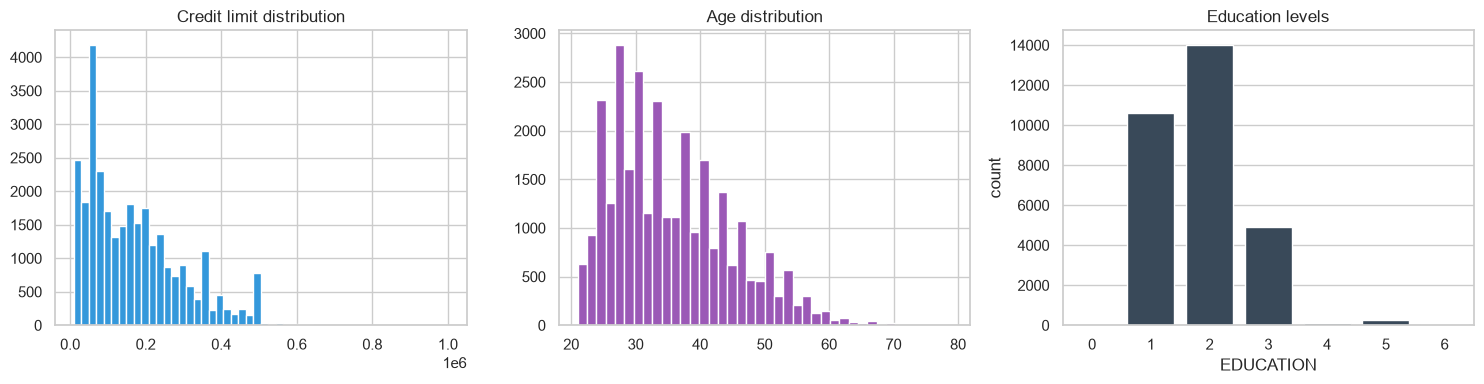

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df['LIMIT_BAL'], bins=50, color='#3498db')
axes[0].set_title('Credit limit distribution')
axes[1].hist(df['AGE'], bins=40, color='#9b59b6')
axes[1].set_title('Age distribution')
sns.countplot(x='EDUCATION', data=df, ax=axes[2], color='#34495e')
axes[2].set_title('Education levels')
plt.tight_layout()
plt.savefig('../reports/figures/01_demographics.png', dpi=110)
plt.show()

## Payment history — the core signal
#
`PAY_0..PAY_6` record repayment status for the last six months
(-1 = paid duly, 0 = revolving, 1..9 = months overdue). A client with
`PAY_0 >= 2` is already behind on the newest bill — historically the
strongest default predictor.

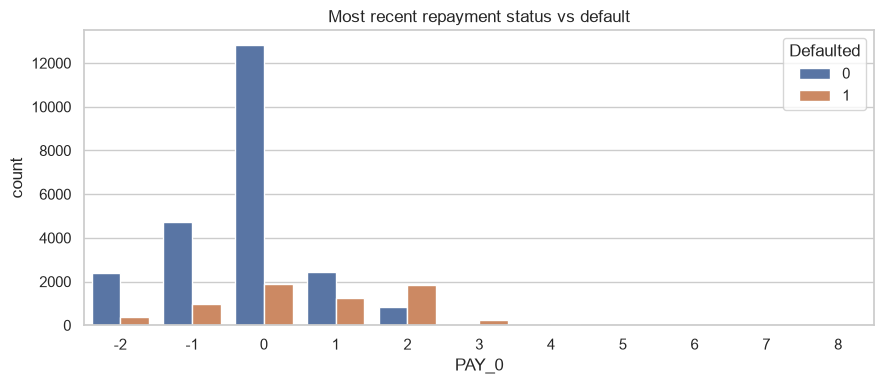

PAY_0
-2    0.132294
-1    0.167781
 0    0.128113
 1    0.339479
 2    0.691414
 3    0.757764
 4    0.684211
 5    0.500000
 6    0.545455
 7    0.777778
 8    0.578947


In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.countplot(x='PAY_0', hue='default_payment_next_month', data=df, ax=ax)
ax.set_title('Most recent repayment status vs default')
ax.legend(title='Defaulted')
plt.tight_layout()
plt.savefig('../reports/figures/01_pay0_vs_default.png', dpi=110)
plt.show()

delay_rates = df.groupby('PAY_0')['default_payment_next_month'].mean()
print(delay_rates.to_string())

## Signed-log transforms tame heavy tails
#
Raw bill/payment amounts span several orders of magnitude. A signed log1p
transform lets linear models use the full range and improves tree split
behaviour slightly.

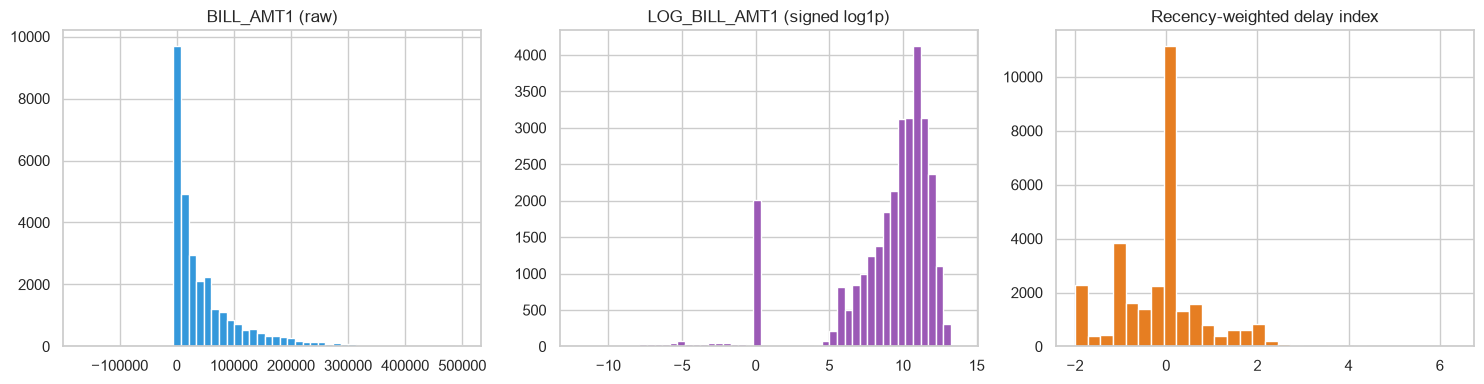

In [5]:
df = add_behavioural_features(df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df['BILL_AMT1'].clip(-5e5, 5e5), bins=50, color='#3498db')
axes[0].set_title('BILL_AMT1 (raw)')
axes[1].hist(df['LOG_BILL_AMT1'], bins=50, color='#9b59b6')
axes[1].set_title('LOG_BILL_AMT1 (signed log1p)')
axes[2].hist(df['DELAY_WEIGHTED'], bins=30, color='#e67e22')
axes[2].set_title('Recency-weighted delay index')
plt.tight_layout()
plt.savefig('../reports/figures/01_log_transforms.png', dpi=110)
plt.show()

## Billing dynamics + correlation heatmap

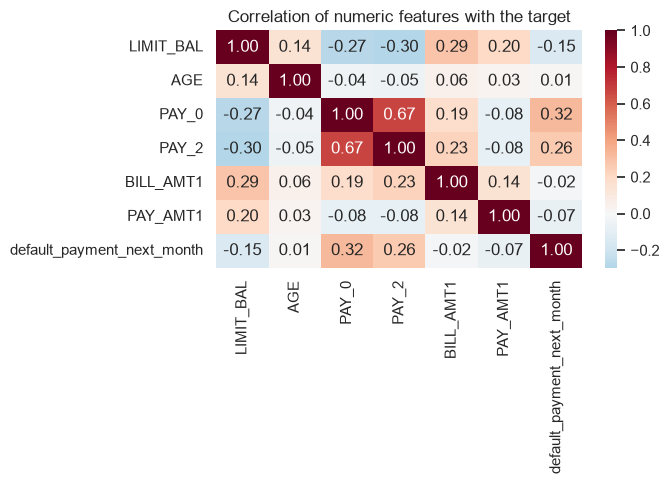

,UTILIZATION,N_MONTHS_DELAY,DELAY_WEIGHTED
default_payment_next_month,,,
0,0.351385,0.504194,-0.299688
1,0.449287,1.996082,0.426677


In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
corr_cols = ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'BILL_AMT1', 'PAY_AMT1',
             'default_payment_next_month']
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlation of numeric features with the target')
plt.tight_layout()
plt.savefig('../reports/figures/01_correlation.png', dpi=110)
plt.show()

eng = df
eng.groupby('default_payment_next_month')[['UTILIZATION', 'N_MONTHS_DELAY', 'DELAY_WEIGHTED']].mean()